In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/ihasan88/customer-behavior-and-churn-prediction-dataset/ecommerce_customer_data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("/kaggle/input/datasets/ihasan88/customer-behavior-and-churn-prediction-dataset/ecommerce_customer_data.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       2000 non-null   int64  
 1   Age               2000 non-null   int64  
 2   Gender            2000 non-null   object 
 3   Annual_Income     2000 non-null   int64  
 4   Spending_Score    2000 non-null   int64  
 5   Membership_Years  2000 non-null   float64
 6   Online_Purchases  2000 non-null   int64  
 7   Discount_Usage    2000 non-null   float64
 8   Churn             2000 non-null   int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 140.8+ KB


,Customer_ID,Age,Gender,Annual_Income,Spending_Score,Membership_Years,Online_Purchases,Discount_Usage,Churn
0,1,56,Male,69812,88,3.2,92,0.43,1
1,2,69,Female,70500,26,4.3,30,0.23,1
2,3,46,Female,99151,17,8.2,199,0.52,0
3,4,32,Male,78643,71,0.6,153,0.25,0
4,5,60,Female,64900,13,6.7,127,0.94,0


Churn
0    68.95
1    31.05
Name: proportion, dtype: float64


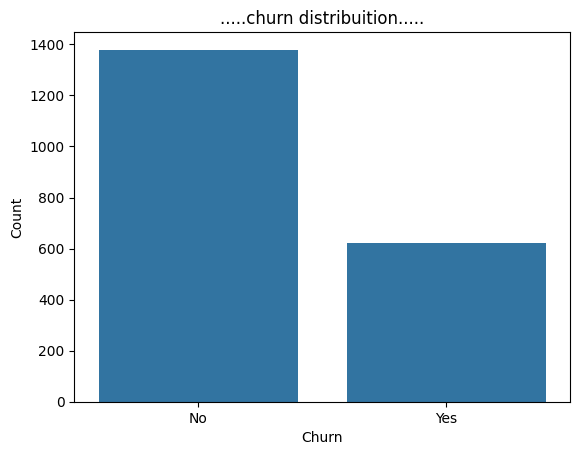

In [4]:
#churn distribuition..........
print(df["Churn"].value_counts(normalize=True)*100)
sns.countplot(data=df,x="Churn")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.xticks([0,1],["No","Yes"])
plt.title(".....churn distribuition.....")
plt.show()
#here we can see that,31.05% customer decided to churn....and this is the concerning for this company
#and the other side we can see 68.95 customer decided to stay with the company....
    

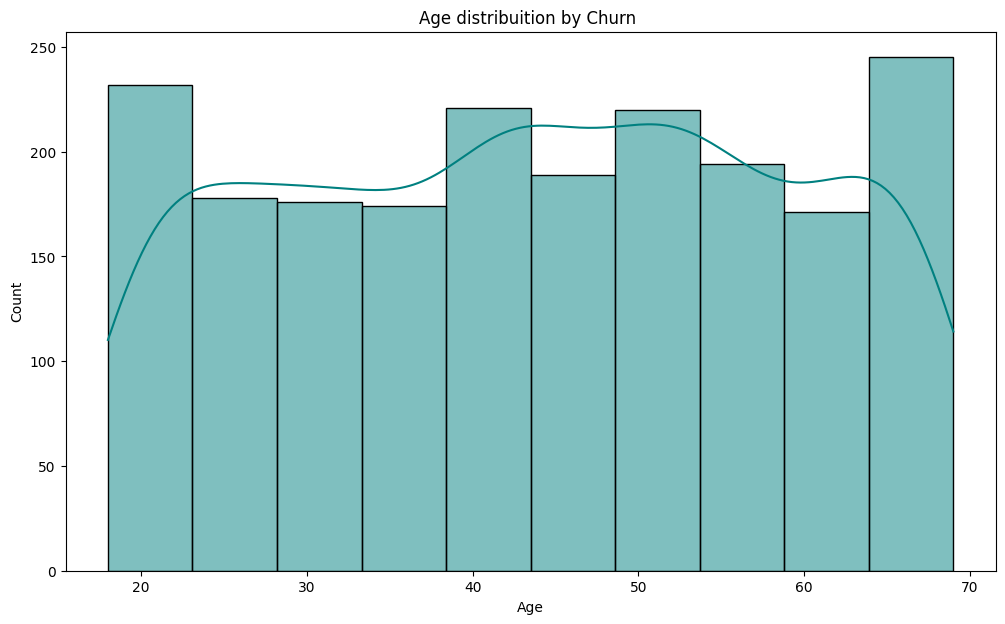

'in this graph, we can see that the age distribution appears fairly uniform across all age groups(20-70),\nmeaning customers are spread evenly,but if we notice strongly we can see that customer in higher \nage group(65-70) appear to have a higher churn tendency compared to other groups......'

In [5]:
#age vs churn
plt.figure(figsize=(12,7))
sns.histplot(df["Age"],bins=10,kde=True,color="teal")
plt.xlabel("Age")
plt.title("Age distribuition by Churn ")
plt.show()
'''in this graph, we can see that the age distribution appears fairly uniform across all age groups(20-70),
meaning customers are spread evenly,but if we notice strongly we can see that customer in higher 
age group(65-70) appear to have a higher churn tendency compared to other groups......'''

Churn           0          1
Gender                      
Female  69.061303  30.938697
Male    68.828452  31.171548


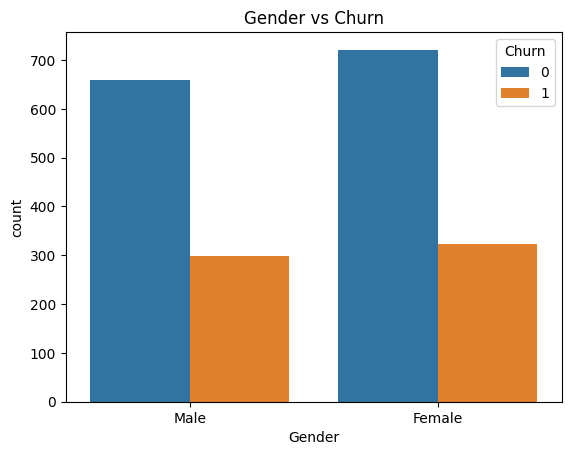

'from the analysis,it is observed that churn rates both male(31.17%) and female(30.93%) customers\nare nearly identical.this indicates that gender does not have an significant impact on customer chum \nbehavior'

In [6]:
#Gender vs Churn
gender_churn=pd.crosstab(df["Gender"],df["Churn"],normalize="index")*100
print(gender_churn)
sns.countplot(x="Gender",hue="Churn",data=df)
plt.title("Gender vs Churn")
plt.show()
'''from the analysis,it is observed that churn rates both male(31.17%) and female(30.93%) customers
are nearly identical.this indicates that gender does not have an significant impact on customer chum 
behavior'''

Churn
0    84248.943437
1    83735.059581
Name: Annual_Income, dtype: float64


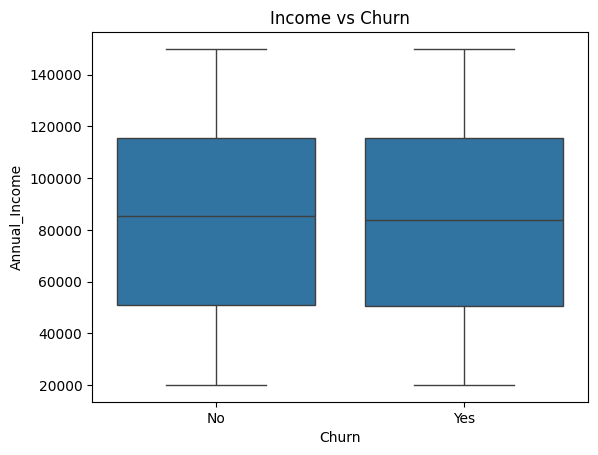

'the average annual income of churned and non-churned customers is nearly the same,indicating \nit does not significantly influence customer churn'

In [7]:
#income vs churn
income_churn=df.groupby("Churn")["Annual_Income"].mean()
print(income_churn)
sns.boxplot(x="Churn",y="Annual_Income",data=df)
plt.xticks([0,1],["No","Yes"])
plt.title("Income vs Churn")
plt.show()
'''the average annual income of churned and non-churned customers is nearly the same,indicating 
it does not significantly influence customer churn'''



In [8]:
#spending score vs churn
spending_score_churn=df.groupby("Churn")["Spending_Score"].mean()
print(spending_score_churn)

Churn
0    50.879623
1    49.491143
Name: Spending_Score, dtype: float64


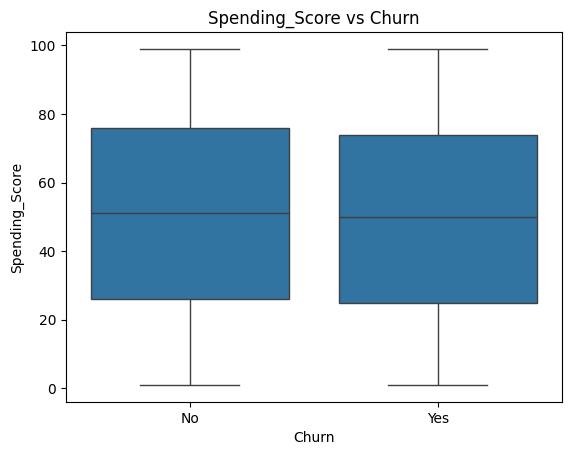

'the spending score of churned and non-churned customers is nearly the same,indicating \nit does not significantly influence customer churn'

In [9]:
sns.boxplot(x="Churn",y="Spending_Score",data=df)
plt.xticks([0,1],["No","Yes"])
plt.title("Spending_Score vs Churn")
plt.show()
'''the spending score of churned and non-churned customers is nearly the same,indicating 
it does not significantly influence customer churn'''



Churn
0    97.812183
1    98.339775
Name: Online_Purchases, dtype: float64


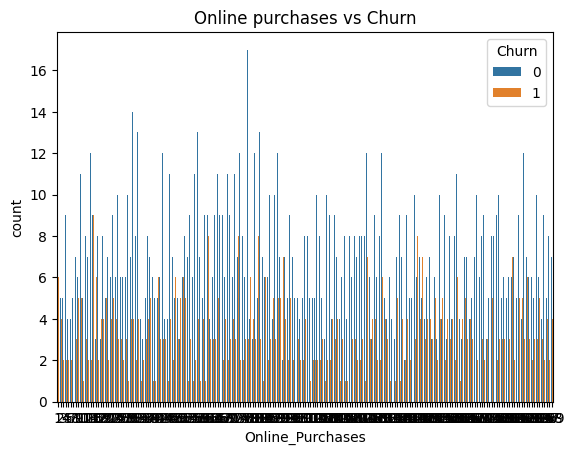

In [10]:
online_purchase_churn=df.groupby("Churn")["Online_Purchases"].mean()
print(online_purchase_churn)
sns.countplot(x="Online_Purchases",hue="Churn",data=df)
plt.title("Online purchases vs Churn")
plt.show()
#online purchase behavior is strongly associated with churn,where customers with lower engagement are more likely to leave

Churn
0    5.296084
1    5.141224
Name: Membership_Years, dtype: float64


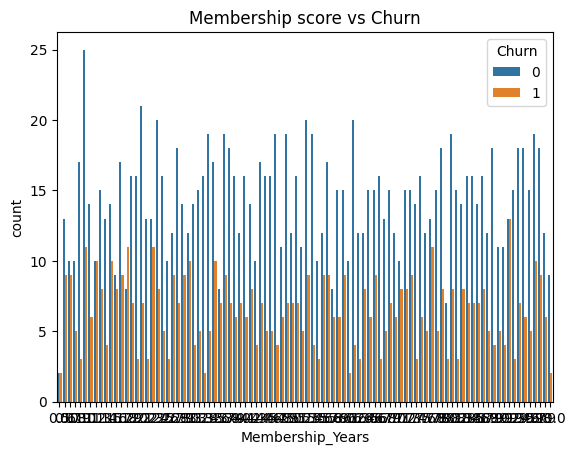

In [11]:
membership_score_churn=df.groupby("Churn")["Membership_Years"].mean()
print(membership_score_churn)
sns.countplot(x="Membership_Years",hue="Churn",data=df)
plt.title("Membership score vs Churn")
plt.show()
#here we can see that customers with shorter membership duration show a higher churn rate,indicating that customers retention stragities should focus on early engagement


Churn
0    0.495453
1    0.475169
Name: Discount_Usage, dtype: float64


'The visualization shows that both churned and non-churned customers are evenly distributed \nacross all leve“The visualization shows that both churned and non-churned customers are evenly\ndistributed across all levels of discount usage, indicating no strong relationship between discount \nusage and churn.”ls of discount usage, indicating no strong relationship between discount usage and churn'

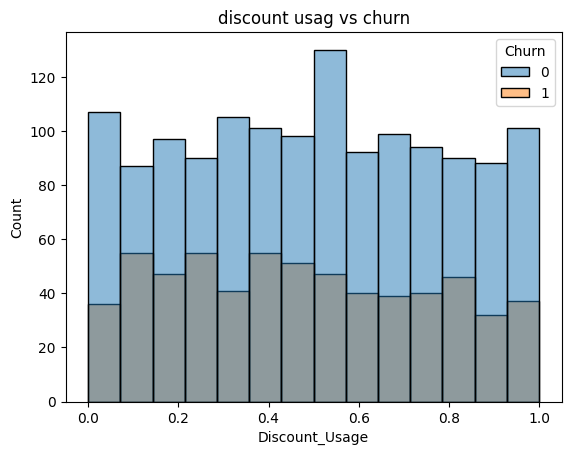

In [12]:
#discount usage vs churn
discount_usage=df.groupby("Churn")["Discount_Usage"].mean()
print(discount_usage)
sns.histplot(x="Discount_Usage",hue="Churn",data=df)
plt.title("discount usag vs churn")
plt.show
'''The visualization shows that both churned and non-churned customers are evenly distributed 
across all leve“The visualization shows that both churned and non-churned customers are evenly
distributed across all levels of discount usage, indicating no strong relationship between discount 
usage and churn.”ls of discount usage, indicating no strong relationship between discount usage and churn'''

                  Customer_ID       Age  Annual_Income  Spending_Score  \
Customer_ID          1.000000 -0.003926       0.023242       -0.019063   
Age                 -0.003926  1.000000      -0.006630        0.017823   
Annual_Income        0.023242 -0.006630       1.000000        0.028632   
Spending_Score      -0.019063  0.017823       0.028632        1.000000   
Membership_Years    -0.004342  0.014373      -0.015236        0.000406   
Online_Purchases    -0.019938 -0.007827       0.012374       -0.042182   
Discount_Usage       0.013934 -0.008761      -0.008325        0.033605   
Churn               -0.002597  0.015985      -0.006351       -0.022618   

                  Membership_Years  Online_Purchases  Discount_Usage     Churn  
Customer_ID              -0.004342         -0.019938        0.013934 -0.002597  
Age                       0.014373         -0.007827       -0.008761  0.015985  
Annual_Income            -0.015236          0.012374       -0.008325 -0.006351  
Spending_

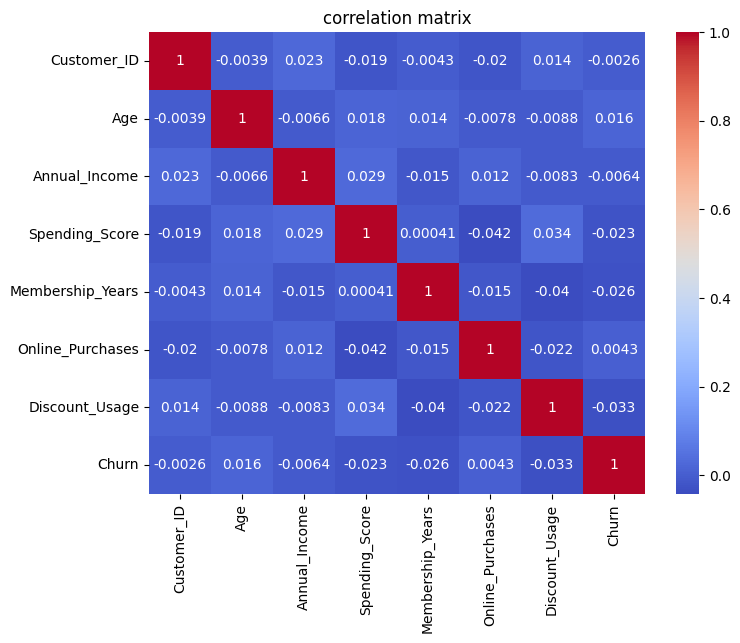

Churn               1.000000
Age                 0.015985
Online_Purchases    0.004260
Customer_ID        -0.002597
Annual_Income      -0.006351
Spending_Score     -0.022618
Membership_Years   -0.025970
Discount_Usage     -0.033340
Name: Churn, dtype: float64

In [13]:
#correlation analysis
corr=df.corr(numeric_only=True)
print(corr)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("correlation matrix")
plt.show()
corr["Churn"].sort_values(ascending=False)

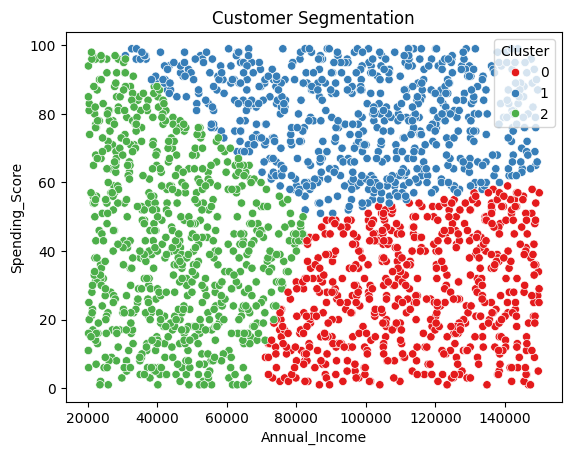

'customers can be divided into three groups based on income and spending behaviour.High income but low\nspending customers are underutilized and need engagement,while high spending  customers are the most valuable and should be retained.low \nincome customers respond better to discounts'

In [14]:
#customer segmentation
x_seg=df[["Annual_Income","Spending_Score"]]
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x_seg)
from sklearn.cluster import KMeans
KMeans=KMeans(n_clusters=3,random_state=42)
df["Cluster"]=KMeans.fit_predict(x_scaled)
sns.scatterplot(x="Annual_Income",y="Spending_Score",hue="Cluster",data=df,palette="Set1")
plt.title("Customer Segmentation")
plt.show()
'''customers can be divided into three groups based on income and spending behaviour.High income but low
spending customers are underutilized and need engagement,while high spending  customers are the most valuable and should be retained.low 
income customers respond better to discounts'''

In [15]:
#old model(baseline)
X=df.drop(["Churn","Customer_ID"],axis=1)
Y=df["Churn"]
X=pd.get_dummies(X,drop_first=True)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report,confusion_matrix
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
model=LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(X_train_scaled,Y_train)
Y_pred=model.predict(X_test_scaled)
accuracy=accuracy_score(Y_test,Y_pred)
y_pred = model.predict(X_test)
print("Accuracy:",accuracy)
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))
importance=model.coef_[0]
for i,v in enumerate(importance):
    print(X.columns[i],":",v)
''' Model Limitations
Low accuracy
Poor performance in detecting churn customers
Possible class imbalance
Limited feature engineering
Logistic Regression may not be sufficient for this dataset'''


Accuracy: 0.485
[[134 132]
 [ 74  60]]
              precision    recall  f1-score   support

           0       0.64      0.50      0.57       266
           1       0.31      0.45      0.37       134

    accuracy                           0.48       400
   macro avg       0.48      0.48      0.47       400
weighted avg       0.53      0.48      0.50       400

Age : 0.025016914204433655
Annual_Income : -0.025057157730346325
Spending_Score : -0.07521031466024863
Membership_Years : -0.05608368904985209
Online_Purchases : 0.03053766840792037
Discount_Usage : -0.05573225083458728
Cluster : 0.04028873362921749
Gender_Male : -0.0025302824745777426


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


' Model Limitations\nLow accuracy\nPoor performance in detecting churn customers\nPossible class imbalance\nLimited feature engineering\nLogistic Regression may not be sufficient for this dataset'

In [16]:
X=df.drop(["Churn","Customer_ID"],axis=1)
Y=df["Churn"]
X=pd.get_dummies(X,drop_first=True)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
from imblearn.over_sampling import SMOTE
sm=SMOTE(random_state=42)
X_train,Y_train=sm.fit_resample(X_train,Y_train)
model=RandomForestClassifier(n_estimators=300,max_depth=10,min_samples_split=5,min_samples_leaf=2,random_state=42,class_weight="balanced")
model.fit(X_train,Y_train)
Y_pred=model.predict(X_test)
accuracy=accuracy_score(Y_test,Y_pred)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5],
}

grid = GridSearchCV(RandomForestClassifier(class_weight='balanced'),
                    param_grid, cv=5, n_jobs=-1)

grid.fit(X_train, Y_train)

print("Best Params:", grid.best_params_)

best_model = grid.best_estimator_
Y_pred = best_model.predict(X_test)




print("acuuracy:",accuracy)
print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred))
importance=model.feature_importances_
feature_importance=pd.DataFrame({
    "feature":X_train.columns,
    "importance":importance
}).sort_values(by="importance",ascending=False)
print(feature_importance)
'''The improved model shows better overall accuracy compared to the previous model; 
however, it still struggles to identify churn customers effectively. Further optimization and
imbalance handling are required to make the model suitable for real-world applications'''

Best Params: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}
acuuracy: 0.58
[[194  72]
 [103  31]]
              precision    recall  f1-score   support

           0       0.65      0.73      0.69       266
           1       0.30      0.23      0.26       134

    accuracy                           0.56       400
   macro avg       0.48      0.48      0.48       400
weighted avg       0.54      0.56      0.55       400

            feature  importance
5    Discount_Usage    0.169437
1     Annual_Income    0.158299
2    Spending_Score    0.153498
4  Online_Purchases    0.147468
3  Membership_Years    0.142382
0               Age    0.137049
7       Gender_Male    0.062478
6           Cluster    0.029389


'The improved model shows better overall accuracy compared to the previous model; \nhowever, it still struggles to identify churn customers effectively. Further optimization and\nimbalance handling are required to make the model suitable for real-world applications'

In [17]:

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

 #Train_test_split (IMPORTANT: stratify use kor)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

 #SMOTE (imbalance fix)
sm = SMOTE(random_state=42)
X_train, Y_train = sm.fit_resample(X_train, Y_train)

#XGBoost model
model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,  # SMOTE use korle eta 1 rakha valo
    random_state=42,
    class_weight="balanced"
)

#  Train
model.fit(X_train, Y_train)

# Probability predict (IMPORTANT for threshold tuning)
Y_prob = model.predict_proba(X_test)[:,1]

#  Threshold change (default 0.5 → 0.3)
Y_pred = (Y_prob > 0.3).astype(int)
#accuracy_score
accuracy=accuracy_score(Y_test,Y_pred)

#  Result
print("accuracy:",accuracy)
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

print("\nClassification Report:")
print(classification_report(Y_test, Y_pred))
'''
Low accuracy
Poor performance in detecting churn customers
Possible class imbalance
Limited feature engineering
 XGBoost may not be sufficient for this dataset'''


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [12:55:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


accuracy: 0.5375
Confusion Matrix:
[[147 119]
 [ 66  68]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.55      0.61       266
           1       0.36      0.51      0.42       134

    accuracy                           0.54       400
   macro avg       0.53      0.53      0.52       400
weighted avg       0.58      0.54      0.55       400



'\nLow accuracy\nPoor performance in detecting churn customers\nPossible class imbalance\nLimited feature engineering\n XGBoost may not be sufficient for this dataset'

#discount usage vs churn


In [18]:
                         #buisness insight
#Customer segmentation insight
'''Customers can be clearly divided into three distinct groups based on income and spending 
behavior: high-value customers, low-engagement customers, and budget customers.
This segmentation helps businesses design targeted strategies for each group'''
#High value customers
'''Customers with high income and high spending scores represent the most valuable segment.
They contribute significantly to overall revenue and should be prioritized through loyalty programs,
premium services, and personalized offers.'''
#Underutilized Customers
'''A group of customers has high income but low spending. This indicates missed revenue
opportunities. Businesses should focus on engaging these customers through targeted promotions,
personalized recommendations, and improved customer experience.'''
#budget customers
'''Customers with low income and moderate/low spending are more price-sensitive. Discount campaigns,
bundle offers, and affordable product options can effectively increase their engagement and purchase
frequency.'''
#Churn risk Customers
'''Customers with low spending, fewer purchases, and shorter membership duration are more likely 
to churn. Early identification of these customers allows businesses to implement retention
strategies such as discounts, reminders, or engagement campaigns'''
#Discout strategy insight
'''Discount usage alone does not strongly differentiate churn behavior. This suggests that random
discounts are not effective. Instead, businesses should apply targeted and personalized
discount strategies.'''
#Engagement is the key driver
'''Customer engagement (spending, purchase frequency, and activity level) plays a critical role
in retention. Increasing engagement can significantly reduce churn and improve customer 
lifetime value.'''

'Customer engagement (spending, purchase frequency, and activity level) plays a critical role\nin retention. Increasing engagement can significantly reduce churn and improve customer \nlifetime value.'